# CS4207 Group 12: Predicting NYC yellow-taxi trip duration

We predict how long a yellow-taxi trip will take (in minutes) from what is known when it starts. This is a regression problem.

**Data:** NYC TLC Yellow Taxi Trip Records, January to April 2026, in `OriginalData_DoNotDelete/`
(source: <https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page>). Column meanings are in [Variables.md](Variables.md).

| Section | Rubric criterion |
|---|---|
| 0. Setup | 6. Reproducible notebook |
| 1. Data cleaning and preprocessing | 1. Data cleaning and preprocessing |
| 2. Sequential baseline | 2. Comparison of sequential and parallel execution (the "before" numbers) |
| 3. Data parallelism | 3. Data parallelism, and 2. the speed-up comparison |
| 4. Task parallelism | 4. Task parallelism (feature extraction, hyperparameter search) |
| 5. Non-determinism | 5. Identifying non-determinism and fixes |
| 6. Results summary | 6. Reproducible notebook, and the numbers on the poster |

How the thresholds were chosen is shown with histograms in [Evidence/Distance&Duration.ipynb](Evidence/Distance&Duration.ipynb).

## 0. Setup

Every path, threshold and seed is set in the configuration cell below, so nothing further down is hard-coded.

In [1]:
import os

# One maths thread per process. Set before NumPy loads, so the speed-ups we measure later
# come from our own worker processes and not from hidden library threads.
for var in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[var] = "1"

import json
import platform
import sys
import time
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits

# The environment variables above only work if NumPy was not loaded yet. An IDE can load it before
# this cell runs, so we also limit the maths library directly. Without this, this process can use
# many threads while the workers use one, and the two add up numbers in a different order.
threadpool_limits(limits=1)
plt.style.use("default")  # a dark IDE theme would otherwise give charts a black background

In [2]:
# ---- Configuration: change things here, not further down ----
SEED = 4207  # cleaning has no randomness; later sections use this

# Thresholds (justified in section 1.3 and in the Evidence notebook)
DURATION_THRESHOLD = 90   # minutes; keep (0, 90]
DISTANCE_THRESHOLD = 40   # miles; keep (0, 40]
MIN_SPEED_MPH = 1         # average speed over the whole trip
MAX_SPEED_MPH = 65        # highest speed limit in New York State
INVALID_ZONE_START = 264  # zones 264 (unknown) and 265 (outside NYC)
RATECODES = [1, 2, 3, 4, 5, 6, 99]  # 99 = null/unknown in the TLC data dictionary
ZONE_IDS = list(range(1, INVALID_ZONE_START))  # the 263 real zones

# One raw file per month. The key is the month the file is meant to hold.
FILE_NAMES = {
    "2026-01": "yellow_tripdata_2026-Jan",
    "2026-02": "yellow_tripdata_2026-Feb",
    "2026-03": "yellow_tripdata_2026-Mar",
    "2026-04": "yellow_tripdata_2026-Apr",
}

# Split by time, never at random: train on the past, test on the future
SPLIT = {
    "train": ["2026-01", "2026-02"],
    "validation": ["2026-03"],
    "test": ["2026-04"],
}

PICKUP, DROPOFF = "tpep_pickup_datetime", "tpep_dropoff_datetime"

# Section 2: features and model
SMOOTHING = 50   # pseudo-trips pulling rare zone pairs towards their borough-pair average
FEATURES = ["trip_distance", "log_distance", "hour_sin", "hour_cos", "is_weekend", "is_flex_fare",
            "avg_borough_hour", "avg_zone_pair", "pace_x_distance"]
N_SHARDS = 8     # the training rows are always cut into this many equal shards
ETA = 0.3        # gradient descent learning rate
STEPS = 300      # gradient descent steps (enough to match the exact least-squares answer)
REPEATS = 3      # timed runs per measurement, after one warm-up run

# Section 3: data parallelism
WORKER_COUNTS = [1, 2, 4, 8]  # 8 shards, so 8 workers is the most that can be busy at once
WARMUP_STEPS = 5              # short run that starts the workers and loads the data into memory before timing

# Section 4: task parallelism (random hyperparameter search)
SEARCH_TRIALS = 12            # independent training runs, one task each
SEARCH_STEPS = 150            # most steps a trial may take
SEARCH_TOL = 1e-6             # a trial stops early once its training error stops improving by this fraction
SEARCH_WORKERS = max(1, min(SEARCH_TRIALS, (os.cpu_count() or 2) - 2))  # leave two cores for the system

# Section 5: non-determinism demonstrations (short runs, so they add under a minute)
DEMO_STEPS = 30                                 # gradient descent steps in the thread-count demonstration
DEMO_THREADS = min(4, os.cpu_count() or 1)      # maths-library threads used to show the thread-count problem

# Only the columns cleaning needs. The other 10 columns are never read from disk.
COLUMNS = [PICKUP, DROPOFF, "trip_distance", "PULocationID", "DOLocationID",
           "VendorID", "RatecodeID", "payment_type", "fare_amount"]

np.random.seed(SEED)
pd.set_option("display.width", 200)

In [3]:
# Works out the project root, so the notebook runs from any folder on anyone's machine
def find_project_root(marker="OriginalData_DoNotDelete", start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"Could not find '{marker}' above {start}")


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "OriginalData_DoNotDelete"
CLEANED_DIR = PROJECT_ROOT / "CleanedData"
CLEANED_DIR.mkdir(exist_ok=True)
FEATURE_DIR = CLEANED_DIR / "features"  # model-ready NumPy arrays (section 2)
FEATURE_DIR.mkdir(exist_ok=True)
FIGURE_DIR = PROJECT_ROOT / "Figures"  # charts for the poster
FIGURE_DIR.mkdir(exist_ok=True)
ZONE_LOOKUP = PROJECT_ROOT / "ReferenceData" / "taxi_zone_lookup.csv"

sys.path.insert(0, str(PROJECT_ROOT))  # so workers.py is found wherever Jupyter was started
import workers  # functions the worker processes run (workers.py, next to this notebook)
print(f"Maths library threads in this process: {workers.blas_threads()}")

# Record the environment so anyone can reproduce the run
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | pyarrow {pa.__version__} | numpy {np.__version__}")
print(f"{platform.platform()} | {os.cpu_count()} CPU cores")
NOTEBOOK_START = time.perf_counter()

Maths library threads in this process: 1
Python 3.14.8 | pandas 3.0.6 | pyarrow 26.0.1 | numpy 2.5.3
Windows-11-10.0.26200-SP0 | 14 CPU cores


## 1. Data cleaning and preprocessing

This section is sequential. The work is split into small functions that handle one month at a time
(`read_month`, `clean_data`, `preprocess`), so the data-parallel version can later run the same functions on each month in parallel.

### 1.1 Inspect the Parquet footers first

A Parquet file keeps its row counts and each column's min, max and null count in a small footer at the end of the file.
Reading only the footer shows us the size of the data and most of its problems without loading any rows.

In [4]:
# Combine the per-row-group statistics in one file's footer into one min / max / null count per column
def footer_stats(path):
    meta = pq.ParquetFile(path).metadata
    stats = {}
    for rg in range(meta.num_row_groups):
        for ci in range(meta.num_columns):
            col = meta.row_group(rg).column(ci)
            s = col.statistics
            if s is None:
                continue
            d = stats.setdefault(col.path_in_schema, {"min": None, "max": None, "nulls": 0})
            d["nulls"] += s.null_count or 0
            if s.has_min_max:
                d["min"] = s.min if d["min"] is None else min(d["min"], s.min)
                d["max"] = s.max if d["max"] is None else max(d["max"], s.max)
    return meta, stats


FOOTER, rows = {}, []
for month, name in FILE_NAMES.items():
    meta, stats = footer_stats(DATA_DIR / f"{name}.parquet")
    FOOTER[month] = stats
    rows.append({"month": month, "rows": meta.num_rows, "row_groups": meta.num_row_groups,
                 "first_pickup": stats[PICKUP]["min"], "last_pickup": stats[PICKUP]["max"],
                 "max_distance": stats["trip_distance"]["max"], "min_fare": stats["fare_amount"]["min"],
                 "null_RatecodeID": stats["RatecodeID"]["nulls"]})

RAW_ROWS = {r["month"]: r["rows"] for r in rows}
print(f"Total raw rows: {sum(RAW_ROWS.values()):,}")
pd.DataFrame(rows).set_index("month")

Total raw rows: 14,908,446


,rows,row_groups,first_pickup,last_pickup,max_distance,min_fare,null_RatecodeID
month,,,,,,,
2026-01,3724889,4,2025-12-31 23:57:29,2026-02-01 00:45:01,269097.48,-2555.2,1088058
2026-02,3399866,4,2026-01-31 23:31:23,2026-03-01 00:51:48,328522.20,-2084.1,1023317
2026-03,3952451,4,2008-12-31 23:03:20,2026-04-01 00:06:25,288381.68,-990.0,945748
2026-04,3831240,4,2001-01-01 09:23:58,2026-05-01 00:01:28,281576.08,-1274.9,799786


The footers already show what needs cleaning:

- **Spill-over pickups:** every file has pickups from the month before or after (`first_pickup`, `last_pickup`).
- **Meter errors:** the longest trip is hundreds of thousands of miles (`max_distance`).
- **Negative fares** (`min_fare`).
- **Flex Fare nulls:** about a quarter of rows have no `RatecodeID` (`null_RatecodeID`).

### 1.2 Load only what we need

We read 9 of the 20 columns. The spill-over filter is passed to the Parquet reader, so rows from the wrong month are dropped while the file is read and never reach pandas.

`fare_amount`, `payment_type` and the drop-off time are loaded only for cleaning and are dropped before saving (see 1.8).

In [5]:
def month_bounds(month):
    start = pd.Timestamp(f"{month}-01")
    return start, start + pd.offsets.MonthBegin(1)


# Reads one month. The filter keeps only pickups inside that month (removes spill-over).
def read_month(month):
    start, end = month_bounds(month)
    us = pa.timestamp("us")  # the files store timestamps in microseconds
    table = pq.read_table(
        DATA_DIR / f"{FILE_NAMES[month]}.parquet",
        columns=COLUMNS,
        filters=[(PICKUP, ">=", pa.scalar(start.to_pydatetime(), us)),
                 (PICKUP, "<", pa.scalar(end.to_pydatetime(), us))],
    )
    return table.to_pandas()

### 1.3 Cleaning rules

The rules run in this order. Each removed row is counted against the first rule that catches it, so the counts add up exactly.

| Rule | Removed when | Why |
|---|---|---|
| Spill-over | pickup is not in the file's month | Records from the month before or after. They would also land on the wrong side of the time-based split. |
| Duration | duration ≤ 0 or > 90 min | Drop-off at or before pickup is impossible. Over 90 min is mostly meters left running (max 5.2 days); 99% of trips are under 72 min. |
| Distance | distance ≤ 0 or > 40 miles | Zero means no movement or a meter fault. Over 40 miles removes meter errors such as 269,097 miles; 99% of trips are under 20 miles. |
| Zones | pickup or drop-off zone is 264 or 265 | "Unknown" and "outside NYC" have no usable location. |
| Speed | average speed < 1 mph or > 65 mph | Catches meter errors that pass the distance and duration rules on their own, e.g. 30 miles in 2 minutes. |
| Fare | fare ≤ 0 | Refunds, disputes and voided trips, not real journeys. Most negative fares are a reversal of another record for the same trip. |
| Duplicate | same vendor, pickup, drop-off, zones and distance as an earlier row | The same trip recorded twice. The first copy is kept. |

The fare is used only to spot bad records. It is never a feature, because the meter calculates it from the trip's time and distance.

In [6]:
DUPLICATE_KEY = ["VendorID", PICKUP, DROPOFF, "PULocationID", "DOLocationID", "trip_distance"]


# returns string for what data was and is currently and what amount was dropped
def report(before, after):
    return (f"Previous Dataset Size: {before:,} \n"
            f"Current Dataset Size: {after:,} \n"
            f"Dropped: {before - after:,} lines ({1 - after / before:.2%})")


# Applies each rule in order and counts how many rows each one removes
def clean_data(dataframe_original):
    dataframe = dataframe_original.copy()
    dataframe["duration_min"] = (dataframe[DROPOFF] - dataframe[PICKUP]).dt.total_seconds() / 60

    steps = [
        ("Duration", lambda d: (d["duration_min"] > 0) & (d["duration_min"] <= DURATION_THRESHOLD)),
        ("Distance", lambda d: d["trip_distance"].between(0, DISTANCE_THRESHOLD, inclusive="right")),
        ("Zones 264/265", lambda d: (d["PULocationID"] < INVALID_ZONE_START) & (d["DOLocationID"] < INVALID_ZONE_START)),
        ("Speed", lambda d: (d["trip_distance"] / (d["duration_min"] / 60)).between(MIN_SPEED_MPH, MAX_SPEED_MPH)),
        ("Fare", lambda d: d["fare_amount"] > 0),
        ("Duplicate", lambda d: ~d.duplicated(DUPLICATE_KEY, keep="first")),
    ]

    removed = {}
    for name, keep in steps:
        before = len(dataframe)
        dataframe = dataframe.loc[keep(dataframe)]
        removed[name] = before - len(dataframe)
    return dataframe, removed

### 1.4 Preprocessing: Flex Fare, categories and features

Rows with `payment_type = 0` are Flex Fare trips, booked in an app at an up-front price.
For these rows the vendors leave `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge` and `Airport_fee` empty
(section 1.6 checks this). They are about a quarter of all trips and their times, zones and distances are fine, so we keep them instead of dropping every null:

- `RatecodeID` nulls become `99`, the data dictionary's code for "null/unknown".
- A new column `is_flex_fare` records which trips were Flex Fare. This is known when the trip is booked, so it is safe to use as a feature.
- The other null columns are never loaded.

Zone IDs and rate codes are labels, not quantities (zone 200 is not "twice" zone 100), so they are stored as categories
with a fixed list of values. Every month then gets the same codes, whichever order the months are processed in.

Two features come from the pickup time, so they are known before the trip starts: `pickup_hour` (0 to 23) and `pickup_dow` (0 = Monday to 6 = Sunday).

In [7]:
# Output columns, in a fixed order. duration_min is the target.
CLEAN_COLUMNS = [PICKUP, "pickup_hour", "pickup_dow", "PULocationID", "DOLocationID",
                 "trip_distance", "RatecodeID", "is_flex_fare", "duration_min"]


def preprocess(dataframe):
    out = pd.DataFrame({
        PICKUP: dataframe[PICKUP],
        "pickup_hour": dataframe[PICKUP].dt.hour.astype("int8"),
        "pickup_dow": dataframe[PICKUP].dt.dayofweek.astype("int8"),
        "PULocationID": pd.Categorical(dataframe["PULocationID"], categories=ZONE_IDS),
        "DOLocationID": pd.Categorical(dataframe["DOLocationID"], categories=ZONE_IDS),
        "trip_distance": dataframe["trip_distance"],
        "RatecodeID": pd.Categorical(dataframe["RatecodeID"].fillna(99).astype("int64"), categories=RATECODES),
        "is_flex_fare": dataframe["payment_type"] == 0,
        "duration_min": dataframe["duration_min"],
    })[CLEAN_COLUMNS]
    # A value missing from a category list would quietly turn into NaN, so stop if that happens
    assert not out.isna().any().any(), "unexpected null after preprocessing"
    return out.reset_index(drop=True)


# Read a cleaned month back with its categories restored (Parquet does not always keep them)
def read_clean(month, columns=None):
    dataframe = pd.read_parquet(CLEANED_DIR / f"{FILE_NAMES[month]}_Cleaned.parquet", columns=columns)
    for col, cats in [("PULocationID", ZONE_IDS), ("DOLocationID", ZONE_IDS), ("RatecodeID", RATECODES)]:
        if col in dataframe:
            dataframe[col] = pd.Categorical(dataframe[col], categories=cats)
    return dataframe

### 1.5 Run the cleaning and report before and after row counts

Each month is read, cleaned, preprocessed and saved to `CleanedData/` on its own, so only one month is in memory at a time.
The spill-over count is the footer row count minus the rows the filtered read returned.

In [8]:
removed_by_month, kept_by_month = {}, {}
start = time.perf_counter()

for month in FILE_NAMES:
    raw = read_month(month)
    removed = {"Spill-over": RAW_ROWS[month] - len(raw)}
    clean, removed_by_rule = clean_data(raw)
    removed.update(removed_by_rule)

    out = preprocess(clean)
    out.to_parquet(CLEANED_DIR / f"{FILE_NAMES[month]}_Cleaned.parquet", index=False)

    removed_by_month[month], kept_by_month[month] = removed, len(out)
    print(f"--- {month} ---\n{report(RAW_ROWS[month], len(out))}\n")
    del raw, clean, out  # free memory before the next month

print(f"Cleaning took {time.perf_counter() - start:.1f}s")

--- 2026-01 ---
Previous Dataset Size: 3,724,889 
Current Dataset Size: 3,454,521 
Dropped: 270,368 lines (7.26%)

--- 2026-02 ---
Previous Dataset Size: 3,399,866 
Current Dataset Size: 3,150,911 
Dropped: 248,955 lines (7.32%)

--- 2026-03 ---
Previous Dataset Size: 3,952,451 
Current Dataset Size: 3,700,191 
Dropped: 252,260 lines (6.38%)

--- 2026-04 ---
Previous Dataset Size: 3,831,240 
Current Dataset Size: 3,618,002 
Dropped: 213,238 lines (5.57%)

Cleaning took 13.9s


In [9]:
# One table: rows removed by each rule, per month and in total
rules = list(next(iter(removed_by_month.values())))
summary = pd.DataFrame(removed_by_month).loc[rules]
summary.loc["Rows before"] = pd.Series(RAW_ROWS)
summary.loc["Rows removed"] = summary.loc[rules].sum()
summary.loc["Rows after"] = pd.Series(kept_by_month)
summary = summary.loc[["Rows before", *rules, "Rows removed", "Rows after"]]
summary["Total"] = summary.sum(axis=1)
summary["% of raw"] = (100 * summary["Total"] / summary.loc["Rows before", "Total"]).round(2)

# Every raw row is either kept or removed by exactly one rule
assert (summary.loc["Rows before"] - summary.loc["Rows removed"] == summary.loc["Rows after"]).all()

summary.to_csv(CLEANED_DIR / "cleaning_report.csv")
summary

,2026-01,2026-02,2026-03,2026-04,Total,% of raw
Rows before,3724889,3399866,3952451,3831240,14908446,100.00
Spill-over,7,16,19,12,54,0.00
Duration,60149,54482,67141,67638,249410,1.67
Distance,125288,123080,120601,93615,462584,3.10
Zones 264/265,22266,19140,20714,20756,82876,0.56
Speed,25548,26551,23257,16541,91897,0.62
Fare,37110,25686,20528,14676,98000,0.66
Duplicate,0,0,0,0,0,0.00
Rows removed,270368,248955,252260,213238,984821,6.61
Rows after,3454521,3150911,3700191,3618002,13923625,93.39


The duplicate rule removes nothing because the fare rule has already dealt with duplicates. In January's raw data, 35,174 of the 35,713 duplicate pairs
are a trip plus its negative-fare reversal, and the rest are caught by the duration or distance rules. We keep the rule as a safety check.

### 1.6 Check the Flex Fare nulls

If the nulls come from Flex Fare, the number of `payment_type = 0` rows should match the null count of each affected column exactly.
The null counts come from the footers, so this only needs to read one column.

In [10]:
flex_rows = []
for month, name in FILE_NAMES.items():
    payment = pq.read_table(DATA_DIR / f"{name}.parquet", columns=["payment_type"])["payment_type"]
    row = {"month": month, "flex_fare_rows": pc.sum(pc.equal(payment, 0)).as_py()}
    for col in ["passenger_count", "RatecodeID", "store_and_fwd_flag", "congestion_surcharge", "Airport_fee"]:
        row[f"nulls_{col}"] = FOOTER[month][col]["nulls"]
    flex_rows.append(row)

flex = pd.DataFrame(flex_rows).set_index("month")
assert all((flex[c] == flex["flex_fare_rows"]).all() for c in flex.columns if c.startswith("nulls_"))
print("The nulls are exactly the Flex Fare rows in every month.")
flex

The nulls are exactly the Flex Fare rows in every month.


,flex_fare_rows,nulls_passenger_count,nulls_RatecodeID,nulls_store_and_fwd_flag,nulls_congestion_surcharge,nulls_Airport_fee
month,,,,,,
2026-01,1088058,1088058,1088058,1088058,1088058,1088058
2026-02,1023317,1023317,1023317,1023317,1023317,1023317
2026-03,945748,945748,945748,945748,945748,945748
2026-04,799786,799786,799786,799786,799786,799786


In [11]:
# Share of Flex Fare trips that survived cleaning, and how their durations compare
flex_after = pd.concat([read_clean(m, ["is_flex_fare", "duration_min"]) for m in FILE_NAMES])
flex_after.groupby("is_flex_fare")["duration_min"].agg(trips="size", median_minutes="median").round(2)

,trips,median_minutes
is_flex_fare,,
False,10492869,12.77
True,3430756,16.18


### 1.7 Train, validation and test split by time

An ETA model predicts future trips, so we split by month instead of at random:
**train = January and February, validation = March, test = April.**
A random split puts trips from the same hour and the same traffic into both train and test, which makes the model look better than it is.
Validation is for choosing models and hyperparameters; the test month is used once, at the end.

In [12]:
# Load one split from the cleaned files
def load_split(name, columns=None):
    return pd.concat([read_clean(m, columns) for m in SPLIT[name]], ignore_index=True)


split_rows = []
for name in SPLIT:
    pickups = load_split(name, [PICKUP])[PICKUP]
    split_rows.append({"split": name, "months": ", ".join(SPLIT[name]), "rows": len(pickups),
                       "first_pickup": pickups.min(), "last_pickup": pickups.max()})

splits = pd.DataFrame(split_rows).set_index("split")
splits["share_%"] = (100 * splits["rows"] / splits["rows"].sum()).round(1)

# The three splits must not overlap in time
assert splits.loc["train", "last_pickup"] < splits.loc["validation", "first_pickup"]
assert splits.loc["validation", "last_pickup"] < splits.loc["test", "first_pickup"]
splits

,months,rows,first_pickup,last_pickup,share_%
split,,,,,
train,"2026-01, 2026-02",6605432,2026-01-01,2026-02-28 23:59:59,47.4
validation,2026-03,3700191,2026-03-01,2026-03-31 23:59:59,26.6
test,2026-04,3618002,2026-04-01,2026-04-30 23:59:59,26.0


### 1.8 Leakage check

| Risk | How we handle it |
|---|---|
| The drop-off time gives away the answer | Used once to work out `duration_min`, then dropped. |
| Fares are calculated from time and distance after the trip | `fare_amount` is used only to remove bad records, then dropped. The other money columns are never loaded. |
| `payment_type` codes such as "dispute" are only known after the trip | Reduced to `is_flex_fare`, which is known at booking. |
| Test data influencing training | Split by time. The thresholds are fixed numbers, not statistics fitted to the data. |
| Average-time features (e.g. borough to borough by hour) | Built in section 2 from the training months only, then looked up for validation and test. |
| `trip_distance` is measured by the meter during the trip | Kept as a stand-in for the planned route distance a real ETA system would get from a map. We say this on the poster. |

In [13]:
LEAKAGE_COLUMNS = {DROPOFF, "fare_amount", "payment_type", "tip_amount", "total_amount", "tolls_amount",
                   "extra", "mta_tax", "improvement_surcharge", "congestion_surcharge", "Airport_fee", "cbd_congestion_fee"}

for month, name in FILE_NAMES.items():
    saved = set(pq.read_schema(CLEANED_DIR / f"{name}_Cleaned.parquet").names)
    assert saved == set(CLEAN_COLUMNS) and not saved & LEAKAGE_COLUMNS
print("No leakage columns in the cleaned files.")

sample = read_clean("2026-01")
display(sample.head())
display(sample.dtypes.to_frame("dtype").T)
sample[["trip_distance", "duration_min"]].describe().T.round(2)

No leakage columns in the cleaned files.


,tpep_pickup_datetime,pickup_hour,pickup_dow,PULocationID,DOLocationID,trip_distance,RatecodeID,is_flex_fare,duration_min
0,2026-01-01 00:54:04,0,3,239,238,0.97,1,False,5.550000
1,2026-01-01 00:34:04,0,3,163,162,0.90,1,False,5.716667
2,2026-01-01 00:57:06,0,3,43,237,1.40,1,False,8.883333
3,2026-01-01 00:15:22,0,3,142,209,5.58,1,False,42.800000
4,2026-01-01 00:27:13,0,3,88,144,2.16,1,False,13.500000


,tpep_pickup_datetime,pickup_hour,pickup_dow,PULocationID,DOLocationID,trip_distance,RatecodeID,is_flex_fare,duration_min
dtype,datetime64[us],int8,int8,category,category,float64,category,bool,float64


,count,mean,std,min,25%,50%,75%,max
trip_distance,3454521.0,3.41,3.99,0.01,1.10,1.90,3.81,40.0
duration_min,3454521.0,16.68,12.49,0.03,8.28,13.42,21.08,90.0


In [14]:
print(f"Section 1 run time: {time.perf_counter() - NOTEBOOK_START:.1f}s on {os.cpu_count()} cores")

Section 1 run time: 15.5s on 14 cores


## 2. Sequential baseline

This section builds the features and trains the model one step at a time on a single process. Its timings are the baseline the parallel versions are compared against.

The model is linear regression trained with batch gradient descent, written in NumPy. We use our own version instead of scikit-learn because
its gradient is a sum over rows, so later the rows can be split into shards, each worker can sum its own shard, and the partial sums can be added up.
The functions that will run on workers are in `workers.py`. The sequential code calls exactly the same functions, so both versions do identical work.

Everything here is fitted on the training months (January and February) and scored on the validation month (March). April stays untouched until the end.

### 2.1 Zones to boroughs

The TLC lookup table gives the borough of each zone. Borough-level averages are more stable than zone-level ones because each borough pair has many more trips.

In [15]:
zones = pd.read_csv(ZONE_LOOKUP, keep_default_na=False)  # zone 265 is literally called "NA"
ZONE_TO_BOROUGH = zones.set_index("LocationID")["Borough"]
zones[zones["LocationID"] < INVALID_ZONE_START].groupby("Borough").size().rename("zones").to_frame().T

Borough,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island
zones,43,61,1,69,69,20


### 2.2 Feature extraction: average trip times from the training months

Three lookup tables are worked out from the training months only. Each one is its own function in `workers.py` and reads just the columns it needs,
so the three are independent of each other. That makes them the feature-extraction tasks we run in parallel later.

| Table | Grouped by | Gives the feature |
|---|---|---|
| Borough-hour | pickup borough, drop-off borough, hour, day of week | `avg_borough_hour`: the usual trip time between those boroughs at that time |
| Zone pair | pickup zone, drop-off zone | `avg_zone_pair`: the usual time for that exact pair of zones |
| Pace | pickup borough, hour, day of week | `pace_x_distance`: minutes per mile in that borough at that time, times the trip's distance |

Grouping by day of week rather than just weekday or weekend lowers the validation RMSE from 6.10 to about 6.07 minutes, because Friday evenings,
Monday mornings and Sundays all behave differently. The pace table is also our measure of rush hour: on weekdays the average taxi speed falls from
about 18 mph at night to about 10 mph between 8:00 and 18:00.

Each function returns sums and counts rather than averages, so results from different pieces of data can be added together before dividing.

Some zone pairs only have a handful of trips, so their average is noisy and leans heavily on the trip's own duration. We smooth it by adding
`SMOOTHING` pseudo-trips at the borough-hour average. A pair with thousands of trips keeps its own average; a pair with three trips ends up close to the borough-hour value.

In [16]:
TRAIN_PATHS = [str(CLEANED_DIR / f"{FILE_NAMES[m]}_Cleaned.parquet") for m in SPLIT["train"]]

# The three feature tasks, in a fixed order. Each one only needs the training files and the zone lookup.
FEATURE_TASKS = [
    ("borough_hour", workers.borough_hour_table),
    ("zone_pair", workers.zone_pair_table),
    ("pace", workers.pace_table),
]


def extract_feature_tables():
    return {name: task(TRAIN_PATHS, str(ZONE_LOOKUP)) for name, task in FEATURE_TASKS}


start = time.perf_counter()
tables = extract_feature_tables()
print(f"Feature tables built in {time.perf_counter() - start:.1f}s")
for name, table in tables.items():
    print(f"  {name:<13} {len(table):>6,} groups")

Feature tables built in 1.9s
  borough_hour   3,864 groups
  zone_pair     43,448 groups
  pace             912 groups


In [17]:
# Fallbacks for groups that never appear in the training months
train_totals = tables["pace"].sum()
GLOBAL_MEAN = train_totals["duration_sum"] / train_totals["count"]
GLOBAL_PACE = train_totals["duration_sum"] / train_totals["distance_sum"]


def build_features(dataframe):
    """Turn cleaned trips into the model's feature matrix (columns in FEATURES order) and target."""
    d = pd.DataFrame({
        "PU_borough": dataframe["PULocationID"].astype(int).map(ZONE_TO_BOROUGH),
        "DO_borough": dataframe["DOLocationID"].astype(int).map(ZONE_TO_BOROUGH),
        "PULocationID": dataframe["PULocationID"].astype(int),
        "DOLocationID": dataframe["DOLocationID"].astype(int),
        "pickup_hour": dataframe["pickup_hour"].astype(int),
        "pickup_dow": dataframe["pickup_dow"].astype(int),
        "is_weekend": (dataframe["pickup_dow"] >= 5).astype(int),
    })

    borough_hour = tables["borough_hour"]
    bh_mean = (borough_hour["duration_sum"] / borough_hour["count"]).rename("avg")
    avg_bh = d.join(bh_mean, on=workers.BOROUGH_HOUR_KEYS)["avg"].fillna(GLOBAL_MEAN).to_numpy()

    zone_pair = d.join(tables["zone_pair"], on=workers.ZONE_PAIR_KEYS)
    pair_sum = zone_pair["duration_sum"].fillna(0).to_numpy()
    pair_count = zone_pair["count"].fillna(0).to_numpy()
    avg_zp = (pair_sum + SMOOTHING * avg_bh) / (pair_count + SMOOTHING)

    pace = tables["pace"]
    pace_mean = (pace["duration_sum"] / pace["distance_sum"]).rename("pace")
    pace_lookup = d.join(pace_mean, on=workers.PACE_KEYS)["pace"].fillna(GLOBAL_PACE).to_numpy()

    distance = dataframe["trip_distance"].to_numpy(dtype=float)
    hour_angle = 2 * np.pi * d["pickup_hour"].to_numpy() / 24  # so 23:00 sits next to 00:00
    columns = {
        "trip_distance": distance,
        "log_distance": np.log1p(distance),
        "hour_sin": np.sin(hour_angle),
        "hour_cos": np.cos(hour_angle),
        "is_weekend": d["is_weekend"].to_numpy(dtype=float),
        "is_flex_fare": dataframe["is_flex_fare"].to_numpy(dtype=float),
        "avg_borough_hour": avg_bh,
        "avg_zone_pair": avg_zp,
        "pace_x_distance": distance * pace_lookup,
    }
    X = np.column_stack([columns[name] for name in FEATURES])
    y = dataframe["duration_min"].to_numpy(dtype=float)
    return X, y

### 2.3 Scale the features and save them for the workers

Gradient descent works best when every feature is on a similar scale, so each column is standardised with the training mean and standard deviation
(using validation statistics here would be leakage).

The arrays are saved as `.npy` files. Workers open them with `mmap_mode="r"`, which reads only the rows a worker needs from disk instead of
copying the whole matrix into every process.

In [18]:
MODEL_COLUMNS = [PICKUP, "pickup_hour", "pickup_dow", "PULocationID", "DOLocationID", "trip_distance", "is_flex_fare", "duration_min"]

start = time.perf_counter()
X_train, y_train = build_features(load_split("train", MODEL_COLUMNS))
FEATURE_MEAN, FEATURE_STD = X_train.mean(axis=0), X_train.std(axis=0)

for split in SPLIT:
    X, y = (X_train, y_train) if split == "train" else build_features(load_split(split, MODEL_COLUMNS))
    np.save(FEATURE_DIR / f"{split}_X.npy", (X - FEATURE_MEAN) / FEATURE_STD)
    np.save(FEATURE_DIR / f"{split}_y.npy", y)
    print(f"{split:<10} {X.shape[0]:>9,} rows x {X.shape[1]} features")
del X_train, y_train, X, y
print(f"Features built and saved in {time.perf_counter() - start:.1f}s")

# Fixed shards: N_SHARDS equal, consecutive row ranges of the training matrix
n_train = len(np.load(FEATURE_DIR / "train_y.npy", mmap_mode="r"))
bounds = np.linspace(0, n_train, N_SHARDS + 1).astype(int)
SHARDS = [(str(FEATURE_DIR / "train_X.npy"), str(FEATURE_DIR / "train_y.npy"), int(a), int(b))
          for a, b in zip(bounds[:-1], bounds[1:])]
print(f"{N_SHARDS} shards of about {n_train // N_SHARDS:,} rows each")

pd.DataFrame({"mean": FEATURE_MEAN, "std": FEATURE_STD}, index=FEATURES).round(3).T

train      6,605,432 rows x 9 features
validation 3,700,191 rows x 9 features
test       3,618,002 rows x 9 features
Features built and saved in 7.1s
8 shards of about 825,679 rows each


,trip_distance,log_distance,hour_sin,hour_cos,is_weekend,is_flex_fare,avg_borough_hour,avg_zone_pair,pace_x_distance
mean,3.380,1.221,-0.265,-0.121,0.300,0.283,17.008,16.754,17.008
std,3.961,0.654,0.656,0.697,0.458,0.451,8.417,9.855,17.432


### 2.4 Linear regression by batch gradient descent

Each step works out the mean squared error gradient over all training rows. The rows are processed shard by shard: `workers.partial_gradient`
returns one shard's sums, and the sums are added in shard order before the weights are updated.

The training loop lives in `workers.py` (`workers.train_gd`) so the hyperparameter-search workers in section 4 can run it too. Its core is:

```python
parts = list(map_fn(partial_gradient, *zip(*shards), [w] * n_shards, [b] * n_shards))
grad_w = sum(p[0] for p in parts)   # added in shard order, never in finishing order
...
w = w - eta * (grad_w / n + lam * w)
```

`map_fn` is Python's built-in `map` here, which runs the shards one after another. In section 3 it becomes a process pool's `map`, which runs them
at the same time. Nothing else changes, so the sequential and parallel versions do the same work.

`lam` adds L2 regularisation (a penalty on large weights). It is 0 here and becomes a hyperparameter in the search in section 4.

In [19]:
def train_gd(shards, eta=ETA, steps=STEPS, lam=0.0, map_fn=map):
    """Batch gradient descent for linear regression (workers.train_gd with this notebook's defaults)."""
    return workers.train_gd(shards, eta, steps, lam=lam, map_fn=map_fn)


def predict(split, w, b):
    return np.load(FEATURE_DIR / f"{split}_X.npy") @ w + b


def scores(y_true, y_pred):
    err = y_pred - y_true
    return {"RMSE (min)": np.sqrt(np.mean(err ** 2)),
            "MAE (min)": np.mean(np.abs(err)),
            "R2": 1 - np.mean(err ** 2) / np.var(y_true)}


w_seq, b_seq, history = train_gd(SHARDS)
y_val = np.load(FEATURE_DIR / "validation_y.npy")
print("Validation:", {k: round(float(v), 3) for k, v in scores(y_val, predict("validation", w_seq, b_seq)).items()})

Validation: {'RMSE (min)': 6.072, 'MAE (min)': 3.951, 'R2': 0.783}


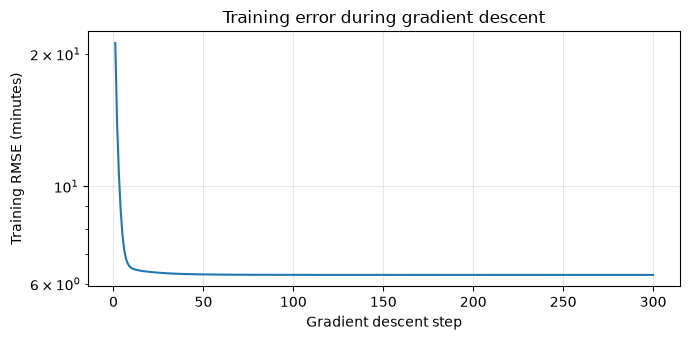

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, STEPS + 1), history)
ax.set_xlabel("Gradient descent step")
ax.set_ylabel("Training RMSE (minutes)")
ax.set_yscale("log")
ax.set_title("Training error during gradient descent")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.5 Check gradient descent found the right answer

Linear regression also has an exact solution (least squares). If gradient descent has converged, its weights should match it.

In [21]:
X_tr = np.load(FEATURE_DIR / "train_X.npy")
y_tr = np.load(FEATURE_DIR / "train_y.npy")
exact = np.linalg.lstsq(np.column_stack([np.ones(len(y_tr)), X_tr]), y_tr, rcond=None)[0]
del X_tr, y_tr

weights = pd.DataFrame({"gradient descent": np.r_[b_seq, w_seq], "exact least squares": exact},
                       index=["intercept", *FEATURES])
weights["difference"] = weights["gradient descent"] - weights["exact least squares"]
print(f"Largest difference in validation predictions: "
      f"{np.abs(predict('validation', w_seq, b_seq) - predict('validation', exact[1:], exact[0])).max():.4f} minutes")
weights.round(4)

Largest difference in validation predictions: 0.0303 minutes


,gradient descent,exact least squares,difference
intercept,17.0077,17.0077,-0.0000
trip_distance,-2.3321,-2.3377,0.0056
log_distance,3.0628,3.0692,-0.0064
hour_sin,-0.5512,-0.5512,-0.0000
hour_cos,-1.2315,-1.2314,-0.0001
is_weekend,-0.4714,-0.4713,-0.0001
is_flex_fare,-0.2277,-0.2282,0.0006
avg_borough_hour,0.6579,0.6591,-0.0013
avg_zone_pair,6.3320,6.3297,0.0023
pace_x_distance,3.7664,3.7670,-0.0005


### 2.6 How good is the model?

Two references on the same validation month:

- Always guessing the training mean. Any useful model has to beat this.
- The group's first model: scikit-learn linear regression with one-hot zones, hour and day of week (from `SequentialAlgorithms/`),
  retrained here on the time-based split instead of the random 80/20 split.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ONEHOT_FEATURES = ["trip_distance", "PULocationID", "DOLocationID", "pickup_hour", "pickup_dow"]
train_df = load_split("train", ONEHOT_FEATURES + ["duration_min"])
val_df = load_split("validation", ONEHOT_FEATURES + ["duration_min"])

start = time.perf_counter()
onehot_model = Pipeline([
    ("prep", ColumnTransformer([
        ("num", "passthrough", ["trip_distance"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["PULocationID", "DOLocationID", "pickup_hour", "pickup_dow"]),
    ])),
    ("reg", LinearRegression()),
]).fit(train_df[ONEHOT_FEATURES], train_df["duration_min"])
onehot_seconds = time.perf_counter() - start

results = pd.DataFrame({
    "Guess the training mean": scores(y_val, np.full(len(y_val), train_df["duration_min"].mean())),
    "One-hot scikit-learn model": scores(y_val, onehot_model.predict(val_df[ONEHOT_FEATURES])),
    "Our gradient descent model": scores(y_val, predict("validation", w_seq, b_seq)),
}).T.round(3)
del train_df, val_df
print(f"The one-hot model took {onehot_seconds:.1f}s to fit")
results

The one-hot model took 37.8s to fit


,RMSE (min),MAE (min),R2
Guess the training mean,13.036,9.289,-0.000
One-hot scikit-learn model,6.943,4.708,0.716
Our gradient descent model,6.072,3.951,0.783


The average-time features do most of the work: they give the model knowledge of typical traffic between places at a given hour, which a single
linear weight per zone cannot capture as well.

### 2.7 Sequential timings

These are the numbers the parallel versions are measured against. Each one is the mean of `REPEATS` runs after one warm-up run;
the warm-up loads the files into the operating system's cache, so the timed runs all start from the same state.

We also check that every run gives exactly the same answer. This model has no randomness: the split is by month and gradient descent always starts
from zero weights. The group's earlier model used a random 80/20 split, so each seed gave a slightly different RMSE; that is one of the sources of
non-determinism we look at later.

In [23]:
def time_it(fn, repeats=REPEATS):
    """Run fn once to warm up, then time the next `repeats` runs. Returns the times and each run's result."""
    fn()
    times, outputs = [], []
    for _ in range(repeats):
        start = time.perf_counter()
        outputs.append(fn())
        times.append(time.perf_counter() - start)
    return times, outputs


table_times, table_runs = time_it(extract_feature_tables)
gd_times, gd_runs = time_it(lambda: train_gd(SHARDS))

# Every timed run must match the first results from 2.2 and 2.4 exactly, not just closely
assert all(run[name].equals(tables[name]) for run in table_runs for name in tables)
assert all(np.array_equal(w, w_seq) and b == b_seq for w, b, _ in gd_runs)
print(f"All {REPEATS} timed runs gave identical feature tables and bit-for-bit identical weights.")

SEQUENTIAL_TIMES = {
    "Feature extraction (3 tables)": table_times,
    f"Gradient descent ({STEPS} steps, {N_SHARDS} shards)": gd_times,
}
pd.DataFrame(SEQUENTIAL_TIMES, index=[f"run {i + 1}" for i in range(REPEATS)]).T.assign(
    mean=lambda t: t.mean(axis=1), std=lambda t: t.std(axis=1)).round(2)

All 3 timed runs gave identical feature tables and bit-for-bit identical weights.


,run 1,run 2,run 3,mean,std
Feature extraction (3 tables),1.87,1.85,1.87,1.86,0.01
"Gradient descent (300 steps, 8 shards)",140.72,93.15,93.27,109.05,22.40


In [24]:
# Saved so later sections, and the poster, use the same baseline numbers
baseline = {"w": w_seq.tolist(), "b": float(b_seq),
            "validation": {k: float(v) for k, v in results.loc["Our gradient descent model"].items()},
            "sequential_times": SEQUENTIAL_TIMES, "cpu_cores": os.cpu_count()}
with open(FEATURE_DIR / "sequential_baseline.json", "w") as f:
    json.dump(baseline, f, indent=1)
print(f"Notebook run time so far: {time.perf_counter() - NOTEBOOK_START:.1f}s")

Notebook run time so far: 587.1s


## 3. Data parallelism: gradient descent across worker processes

### 3.1 Design

Each gradient descent step needs the sum of the gradient over all 6.6 million training rows. A sum can be split up: each worker sums its own rows,
and adding the workers' totals gives the same answer as summing everything in one place. So the work is split by rows.

**Sharding scheme.** The training rows are cut into `N_SHARDS` = 8 equal, consecutive blocks (set up in section 2.3).

- Equal sizes keep the load balanced: every shard has about 826,000 rows, so no worker waits on a bigger one.
- Consecutive blocks mean each worker reads one continuous piece of the `.npy` file.
- The number of shards stays fixed whatever the number of workers. With 2 workers each handles 4 shards; with 8 workers each handles 1.
  Because the shards and the order their sums are added in never change, every worker count does exactly the same arithmetic in the same order,
  so the weights should come out bit-for-bit identical, not just close.

**Same function on every shard.** Every worker runs `workers.partial_gradient`, the function section 2 already used one shard at a time.
It returns four partial results for its shard: the gradient sum for the weights, the gradient sum for the bias, the squared error and the row count.

**Combining the results.** `ProcessPoolExecutor.map` returns results in the order the shards were submitted, not the order workers finish.
`train_gd` adds them in that order, divides by the total row count and updates the weights once per step.

**Memory.** Workers open the training matrix with `mmap_mode="r"`, so each process only touches the rows of the shard it is working on.
The operating system keeps the file in its shared cache after the first read, so the data is held in memory once, not once per worker.

The code is the same `train_gd` as section 2. The only change is `map_fn`: a process pool's `map` instead of Python's built-in `map`.

### 3.2 Run it with 1, 2, 4 and 8 workers

For each worker count we start a pool, run a short warm-up (which starts the worker processes and pulls the data into memory),
then time `REPEATS` full training runs of `STEPS` steps. Every run's weights are compared with the sequential weights from section 2.

The 1-worker run does the same work as section 2 but through a pool, so the gap between the two shows the cost of the pool itself.

Each pool also reports how many threads its workers' maths library uses. It must match this process (1), because NumPy's maths library
adds numbers up in a different order with a different thread count, and the weights would then differ in their last digits.

In [25]:
def benchmark_parallel_gd(n_workers):
    """Time REPEATS full training runs on a pool of n_workers. Returns the times, the pool start-up time and each run's weights."""
    start = time.perf_counter()
    with ProcessPoolExecutor(max_workers=n_workers) as pool:
        list(pool.map(workers.ping, range(n_workers)))  # makes the pool start its processes now
        startup = time.perf_counter() - start
        worker_threads = set(pool.map(workers.blas_threads, range(n_workers)))
        assert worker_threads == {workers.blas_threads()}, f"workers use {worker_threads} maths threads, this process {workers.blas_threads()}"
        train_gd(SHARDS, steps=WARMUP_STEPS, map_fn=pool.map)  # warm-up, not timed

        times, weights = [], []
        for _ in range(REPEATS):
            start = time.perf_counter()
            w, b, _ = train_gd(SHARDS, map_fn=pool.map)
            times.append(time.perf_counter() - start)
            weights.append((w, b))
    return times, startup, weights


parallel_runs = {}
for n_workers in WORKER_COUNTS:
    times, startup, weights = benchmark_parallel_gd(n_workers)
    identical = all(np.array_equal(w, w_seq) and b == b_seq for w, b in weights)
    largest_diff = max(max(np.abs(w - w_seq).max(), abs(b - b_seq)) for w, b in weights)
    parallel_runs[n_workers] = {"times": times, "startup": startup, "identical": identical}
    print(f"{n_workers} worker(s): mean {np.mean(times):6.2f}s | pool start-up {startup:.2f}s | "
          f"same weights as sequential: {identical} (largest difference {largest_diff:.1e})")

assert all(r["identical"] for r in parallel_runs.values()), "a parallel run gave different weights"

1 worker(s): mean 101.79s | pool start-up 0.55s | same weights as sequential: True (largest difference 0.0e+00)
2 worker(s): mean  58.00s | pool start-up 0.65s | same weights as sequential: True (largest difference 0.0e+00)
4 worker(s): mean  32.90s | pool start-up 0.62s | same weights as sequential: True (largest difference 0.0e+00)
8 worker(s): mean  23.62s | pool start-up 0.75s | same weights as sequential: True (largest difference 0.0e+00)


### 3.3 Speed-up and efficiency

Speed-up is the sequential time (section 2.7) divided by the parallel time. Efficiency is speed-up divided by the number of workers:
100% would mean every extra worker is fully used.

In [26]:
seq_times = SEQUENTIAL_TIMES[f"Gradient descent ({STEPS} steps, {N_SHARDS} shards)"]
T_SEQ = np.mean(seq_times)

speedup = pd.DataFrame(
    [{"workers": 0, "mean (s)": T_SEQ, "std (s)": np.std(seq_times), "pool start-up (s)": np.nan, "identical weights": True}] +
    [{"workers": n, "mean (s)": np.mean(r["times"]), "std (s)": np.std(r["times"]),
      "pool start-up (s)": r["startup"], "identical weights": r["identical"]} for n, r in parallel_runs.items()]
).set_index("workers").rename(index={0: "sequential"})
speedup["speed-up"] = T_SEQ / speedup["mean (s)"]
speedup["efficiency"] = speedup["speed-up"] / speedup.index.map(lambda n: 1 if n == "sequential" else n)
speedup.round(3)

,mean (s),std (s),pool start-up (s),identical weights,speed-up,efficiency
workers,,,,,,
sequential,109.047,22.398,NaN,True,1.000,1.000
1,101.787,10.898,0.545,True,1.071,1.071
2,57.999,8.038,0.649,True,1.880,0.940
4,32.905,0.030,0.622,True,3.314,0.829
8,23.620,0.153,0.749,True,4.617,0.577


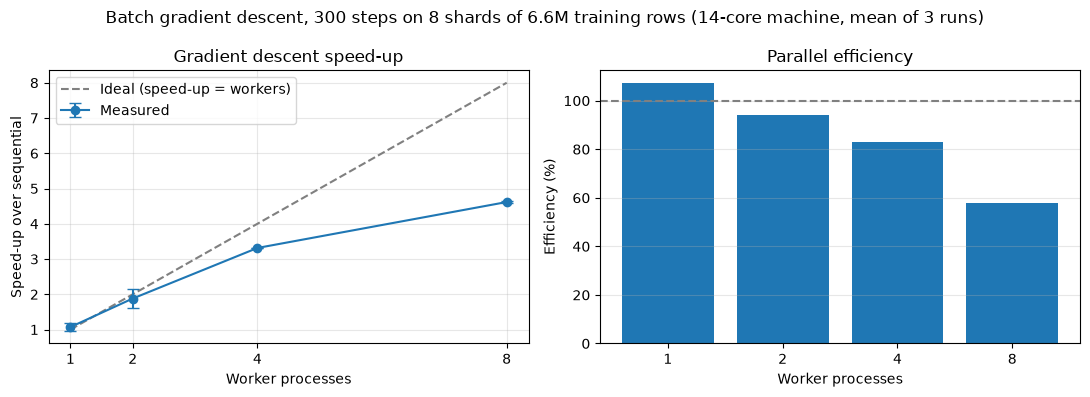

In [27]:
counts = np.array(WORKER_COUNTS)
measured = np.array([T_SEQ / np.mean(parallel_runs[n]["times"]) for n in WORKER_COUNTS])
errors = np.array([T_SEQ * np.std(parallel_runs[n]["times"]) / np.mean(parallel_runs[n]["times"]) ** 2 for n in WORKER_COUNTS])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(counts, counts, "--", color="grey", label="Ideal (speed-up = workers)")
ax1.errorbar(counts, measured, yerr=errors, marker="o", capsize=4, label="Measured")
ax1.set_xlabel("Worker processes")
ax1.set_ylabel("Speed-up over sequential")
ax1.set_xticks(counts)
ax1.set_title("Gradient descent speed-up")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.bar([str(n) for n in counts], 100 * measured / counts)
ax2.axhline(100, ls="--", color="grey")
ax2.set_xlabel("Worker processes")
ax2.set_ylabel("Efficiency (%)")
ax2.set_title("Parallel efficiency")
ax2.grid(alpha=0.3, axis="y")

fig.suptitle(f"Batch gradient descent, {STEPS} steps on {N_SHARDS} shards of 6.6M training rows ({os.cpu_count()}-core machine, mean of {REPEATS} runs)")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "speedup_gradient_descent.png", dpi=200)
plt.show()

### 3.4 Why the speed-up is below ideal

**Amdahl's law.** If a fraction $p$ of the work can run in parallel and the rest cannot, the best speed-up with $n$ workers is

$$S(n) = \frac{1}{(1 - p) + p / n}$$

Rearranging gives $p = \dfrac{1 - 1/S}{1 - 1/n}$, so each measured speed-up gives an estimate of $p$. We also measure the main overheads directly:

- **Process start-up:** creating the worker processes (measured in 3.2).
- **Communication:** every step sends the weights to each shard's task and gets four results back. We time a pool sending
  the same number of empty tasks (`workers.ping`) to see what that messaging costs on its own.
- **Serial work in each step:** adding the 8 partial results and updating 9 weights. This runs on the main process only.
- **Shared memory bandwidth:** each step reads the whole 475 MB training matrix. Extra workers add arithmetic, but they all read through the same memory system.

In [28]:
TASKS_PER_RUN = STEPS * N_SHARDS
overheads = []
for n_workers in WORKER_COUNTS:
    with ProcessPoolExecutor(max_workers=n_workers) as pool:
        list(pool.map(workers.ping, range(n_workers)))
        start = time.perf_counter()
        for _ in range(STEPS):  # one round of tasks per gradient descent step, like train_gd
            list(pool.map(workers.ping, range(N_SHARDS)))
        messaging = time.perf_counter() - start

    S = T_SEQ / np.mean(parallel_runs[n_workers]["times"])
    p = (1 - 1 / S) / (1 - 1 / n_workers) if n_workers > 1 else np.nan
    overheads.append({"workers": n_workers, "speed-up": S, "estimated parallel fraction p": p,
                      "pool start-up (s)": parallel_runs[n_workers]["startup"],
                      f"messaging for {TASKS_PER_RUN:,} empty tasks (s)": messaging})

overheads = pd.DataFrame(overheads).set_index("workers")
P_EST = overheads["estimated parallel fraction p"].dropna().mean()
print(f"Average estimated parallel fraction p = {P_EST:.3f}, "
      f"so Amdahl's law caps the speed-up at about {1 / (1 - P_EST):.1f}x however many workers we add.")
print(f"The pool with 1 worker took {speedup.loc[1, 'mean (s)'] - T_SEQ:+.2f}s compared with plain sequential code: "
      f"that is the cost of sending tasks to another process instead of calling the function directly.")
overheads.round(3)

Average estimated parallel fraction p = 0.921, so Amdahl's law caps the speed-up at about 12.6x however many workers we add.
The pool with 1 worker took -7.26s compared with plain sequential code: that is the cost of sending tasks to another process instead of calling the function directly.


,speed-up,estimated parallel fraction p,pool start-up (s),"messaging for 2,400 empty tasks (s)"
workers,,,,
1,1.071,NaN,0.545,0.228
2,1.880,0.936,0.649,0.221
4,3.314,0.931,0.622,0.212
8,4.617,0.895,0.749,0.211


How to read these numbers:

- The **1-worker pool** does the same work as the sequential version plus the messaging, so any extra time it takes is pure overhead.
- **Messaging** grows with the number of steps, not the size of the data, so it matters less on bigger data and more with more, smaller steps.
- If the estimated $p$ falls as workers are added, the overhead is growing with the worker count (more processes competing for the
  same memory bandwidth and more messages to coordinate), not just a fixed serial part. Amdahl's law with a single $p$ is a simplification.
- **Load imbalance** is small because the shards are equal. With 8 shards, 3 workers would be uneven (3 + 3 + 2 shards); that is why we only use worker counts that divide 8.

In [29]:
# Saved for the poster, so every number on it comes from this run
parallel_summary = {
    "sequential_mean_s": float(T_SEQ),
    "parallel": {str(n): {"times": r["times"], "startup_s": r["startup"], "identical": bool(r["identical"]),
                          "speedup": float(T_SEQ / np.mean(r["times"]))} for n, r in parallel_runs.items()},
    "estimated_parallel_fraction": float(P_EST),
    "cpu_cores": os.cpu_count(),
}
with open(FEATURE_DIR / "parallel_results.json", "w") as f:
    json.dump(parallel_summary, f, indent=1)
print(f"Notebook run time so far: {time.perf_counter() - NOTEBOOK_START:.1f}s")

Notebook run time so far: 1246.4s


## 4. Task parallelism: independent jobs run at the same time

Section 3 split **one job** (a gradient step) across workers: same function, different rows, results added into one answer.
Task parallelism runs **different, independent jobs** at the same time, each producing its own result. We use two patterns from the rubric.

| | Feature extraction (4.1) | Hyperparameter search (4.2) |
|---|---|---|
| Tasks | 3: one per average-time table | 12: one complete training run per setting |
| Why independent | Each table reads the training files itself and groups them its own way; no table needs another's output | Each trial trains its own model from zero; the training data is only read, never changed |
| Combined how | Tables collected in submission order, joined into the features by name | Each trial returns its validation score; the best is chosen afterwards |

The feature tasks follow the group's earlier column-by-column feature extraction script: each feature is computed as its own task and the results are put back in a fixed order.

Results are always read back in the order the tasks were **submitted** (`[f.result() for f in futures]`), not the order they finish,
so the output never depends on which worker happened to be quickest.

### 4.1 Feature extraction: three tables at once

One worker per table. The pool is started before timing (its start-up is reported separately), then we time `REPEATS` runs after a warm-up,
as in section 3. Each task also reports how long it took on its own, which shows how uneven the tasks are.

In [30]:
def extract_feature_tables_parallel(pool):
    """Submit one task per feature table; read the results back in submission order."""
    futures = [pool.submit(workers.feature_task, name, TRAIN_PATHS, str(ZONE_LOOKUP)) for name, _ in FEATURE_TASKS]
    results = [f.result() for f in futures]
    tables_par = {name: table for (name, _), (table, _, _) in zip(FEATURE_TASKS, results)}
    task_times = {name: seconds for (name, _), (_, seconds, _) in zip(FEATURE_TASKS, results)}
    return tables_par, task_times


start = time.perf_counter()
with ProcessPoolExecutor(max_workers=len(FEATURE_TASKS)) as pool:
    list(pool.map(workers.ping, range(len(FEATURE_TASKS))))
    feature_startup = time.perf_counter() - start
    extract_feature_tables_parallel(pool)  # warm-up
    feature_times, feature_runs = [], []
    for _ in range(REPEATS):
        start = time.perf_counter()
        feature_runs.append(extract_feature_tables_parallel(pool))
        feature_times.append(time.perf_counter() - start)

# The parallel tables must equal the sequential ones from section 2.2 exactly
assert all(run[name].equals(tables[name]) for run, _ in feature_runs for name in tables)

seq_feature = np.mean(SEQUENTIAL_TIMES["Feature extraction (3 tables)"])
task_times = feature_runs[-1][1]
print(f"Identical to the sequential tables in all {REPEATS} runs.")
print(f"Sequential {seq_feature:.2f}s | parallel {np.mean(feature_times):.2f}s (± {np.std(feature_times):.2f}) | "
      f"speed-up {seq_feature / np.mean(feature_times):.2f}x | pool start-up {feature_startup:.2f}s")
print(f"Best possible with these tasks: {sum(task_times.values()) / max(task_times.values()):.2f}x "
      f"(total task time / slowest task)")
pd.Series(task_times, name="seconds on its own").round(2).to_frame().T

Identical to the sequential tables in all 3 runs.
Sequential 1.86s | parallel 0.94s (± 0.02) | speed-up 1.99x | pool start-up 0.57s
Best possible with these tasks: 2.16x (total task time / slowest task)


,borough_hour,zone_pair,pace
seconds on its own,0.94,0.38,0.71


With three tasks, the speed-up can never pass 3, and in practice it is capped by the **slowest** task: the others finish and wait.
The work here is also only a few seconds, so reading the files and starting processes take a large share of it. That is Amdahl's law again:
when the parallel part is small, the fixed costs decide the result.

### 4.2 Hyperparameter search: 12 training runs at once

Each trial draws a learning rate (0.02 to 0.6, on a log scale) and an L2 strength (0.00001 to 0.1), trains on January and February,
and is scored on March. A trial stops early when its training error stops improving, or as soon as it starts to grow (the learning rate is too
high and it is diverging: with a safe learning rate the error only ever goes down), so trials take different amounts of time.

Each trial draws its settings from a random generator seeded with `SEED + trial number`. Every run of the notebook therefore tries the same
12 settings, and it does not matter which worker runs which trial (section 5 shows what happens without this).

To estimate how long the 12 trials would take one after another, we first time 20 training steps and one validation scoring in this process,
with nothing else running. The estimate is that step time multiplied by every trial's step count, plus one scoring per trial. Running all 12
trials one by one would add several minutes to the notebook for the same information.

In [31]:
VAL_PATHS = (str(FEATURE_DIR / "validation_X.npy"), str(FEATURE_DIR / "validation_y.npy"))


def random_search(pool, seed=SEED):
    """Run every trial as its own task; read the results back in trial order."""
    futures = [pool.submit(workers.run_trial, t, SHARDS, VAL_PATHS, SEARCH_STEPS, SEARCH_TOL, seed)
               for t in range(SEARCH_TRIALS)]
    return [f.result() for f in futures]


# Time 20 steps and one scoring on their own, for the sequential estimate
start = time.perf_counter()
workers.train_gd(SHARDS, ETA, 20)
seconds_per_step_alone = (time.perf_counter() - start) / 20
start = time.perf_counter()
scores(y_val, predict("validation", w_seq, b_seq))
seconds_per_scoring = time.perf_counter() - start

with ProcessPoolExecutor(max_workers=SEARCH_WORKERS) as pool:
    list(pool.map(workers.ping, range(SEARCH_WORKERS)))
    assert set(pool.map(workers.blas_threads, range(SEARCH_WORKERS))) == {workers.blas_threads()}
    start = time.perf_counter()
    trials = random_search(pool)
    search_wall = time.perf_counter() - start

trial_table = pd.DataFrame([{k: v for k, v in t.items() if k not in ("w", "b", "train_seconds", "score_seconds")}
                            for t in trials]).set_index("trial")
trial_table["worker"] = trial_table["pid"].map({pid: i + 1 for i, pid in enumerate(dict.fromkeys(trial_table["pid"]))})
trial_table = trial_table.drop(columns="pid")
best = trials[int(trial_table["val_rmse"].idxmin())]

sequential_estimate = seconds_per_step_alone * trial_table["steps"].sum() + seconds_per_scoring * SEARCH_TRIALS
print(f"{SEARCH_TRIALS} trials on {SEARCH_WORKERS} workers took {search_wall:.1f}s. "
      f"One after another they would take about {sequential_estimate:.1f}s "
      f"({sequential_estimate / search_wall:.2f}x speed-up).")
print(f"Best on March: trial {best['trial']} (learning rate {best['eta']:.3f}, L2 {best['lam']:.1e}), "
      f"validation RMSE {best['val_rmse']:.3f} min")
trial_table.style.format({"eta": "{:.3f}", "lam": "{:.1e}", "val_rmse": "{:.3f}", "seconds": "{:.1f}"})

12 trials on 12 workers took 79.6s. One after another they would take about 428.3s (5.38x speed-up).
Best on March: trial 5 (learning rate 0.135, L2 5.9e-04), validation RMSE 6.069 min


,eta,lam,steps,stopped,val_rmse,seconds,worker
trial,,,,,,,
0,0.600,6.5e-04,3,diverged,38.387,1.8,1
1,0.032,2.1e-04,150,step limit,6.152,79.0,2
2,0.021,1.5e-02,150,step limit,6.229,79.3,3
3,0.304,2.5e-04,145,converged,6.071,76.8,4
4,0.062,1.6e-04,150,step limit,6.095,78.9,5
5,0.135,5.9e-04,150,step limit,6.069,78.1,6
6,0.487,1.4e-03,5,diverged,14.739,3.1,7
7,0.027,1.8e-05,150,step limit,6.173,78.9,8
8,0.022,1.0e-04,150,step limit,6.204,79.3,9


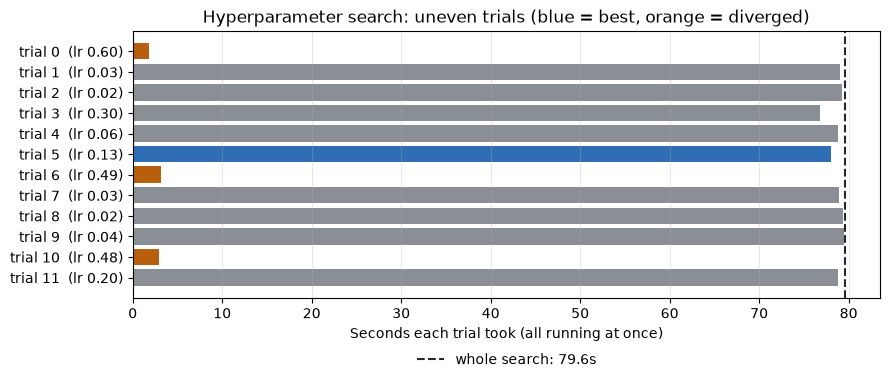

In [32]:
order = trial_table.index
colours = ["#2F6DB5" if t == best["trial"] else ("#B85F0E" if trial_table.loc[t, "stopped"] == "diverged" else "#8A8F96")
           for t in order]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh([f"trial {t}  (lr {trial_table.loc[t, 'eta']:.2f})" for t in order], trial_table["seconds"], color=colours)
ax.axvline(search_wall, ls="--", color="#23272E", label=f"whole search: {search_wall:.1f}s")
ax.invert_yaxis()
ax.set_xlabel("Seconds each trial took (all running at once)")
ax.set_title("Hyperparameter search: uneven trials (blue = best, orange = diverged)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), frameon=False)
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
fig.savefig(FIGURE_DIR / "task_parallel_search.png", dpi=200)
plt.show()

**Load imbalance.** The whole search finishes only when the slowest trial does. Trials that diverge stop after a few steps and their worker
sits idle; trials with a small learning rate run the full `SEARCH_STEPS`. With more trials than workers, a worker that finishes early would pick
up the next trial, which evens this out; with one trial per worker, idle time is the cost.

**Shared memory bandwidth.** Every trial reads the full 475 MB training matrix on every step, so trials running together compete for memory
bandwidth, as the workers did in section 3. That is why a trial takes longer here than on its own.

### 4.3 Final check on April (the test month)

The best setting was chosen on March only. Now, once, both it and the section 2 model are scored on April, which no part of the notebook has used before.

In [33]:
y_test = np.load(FEATURE_DIR / "test_y.npy")
final = pd.DataFrame({
    "Section 2 model (learning rate 0.3, no L2)": scores(y_test, predict("test", w_seq, b_seq)),
    f"Best from the search (trial {best['trial']})": scores(y_test, predict("test", best["w"], best["b"])),
}).T.round(3)

task_summary = {
    "feature_extraction": {"sequential_s": float(seq_feature), "parallel_times": feature_times,
                           "startup_s": feature_startup, "task_seconds": task_times},
    "search": {"workers": SEARCH_WORKERS, "wall_s": search_wall, "sequential_estimate_s": float(sequential_estimate),
               "best": {k: best[k] for k in ("trial", "eta", "lam", "val_rmse", "steps")},
               "trials": trial_table.reset_index().to_dict(orient="records")},
    "test": {k: {m: float(v) for m, v in row.items()} for k, row in final.iterrows()},
}
with open(FEATURE_DIR / "task_parallel_results.json", "w") as f:
    json.dump(task_summary, f, indent=1, default=float)

test_rmse = final["RMSE (min)"]
print(f"On April the two models differ by {abs(test_rmse.iloc[0] - test_rmse.iloc[1]):.3f} min RMSE, "
      f"so tuning the learning rate and L2 changes little: the features, not the settings, limit this model.")
print(f"April's error is {test_rmse.iloc[0] - results.loc['Our gradient descent model', 'RMSE (min)']:+.3f} min "
      f"compared with March: the model is a little less accurate the further it gets from its training months.")
print(f"Notebook run time so far: {time.perf_counter() - NOTEBOOK_START:.1f}s")
final

On April the two models differ by 0.004 min RMSE, so tuning the learning rate and L2 changes little: the features, not the settings, limit this model.
April's error is +0.312 min compared with March: the model is a little less accurate the further it gets from its training months.
Notebook run time so far: 1338.6s


,RMSE (min),MAE (min),R2
"Section 2 model (learning rate 0.3, no L2)",6.384,4.208,0.768
Best from the search (trial 5),6.388,4.221,0.768


## 5. Non-determinism: finding it and fixing it

Non-determinism means the same code on the same data gives a different answer from one run to the next. We found two sources in our
work. For each one, the fix is removed for a moment so its effect can be seen, then put back. Each demonstration is short (a few steps of
gradient descent), so the section adds under a minute.

| # | Source | How we found it |
|---|---|---|
| 1 | The maths library's thread count | By accident: our first full run of section 3 failed its "same weights as sequential" check (saved in `Evidence/Failed_run_thread_mismatch.ipynb`) |
| 2 | Unseeded random choices | The group's first model gave a different RMSE for every random split; here we show it in the hyperparameter search |

Results are also always collected in the order tasks were submitted, never the order they finish (`pool.map` in section 3,
`[f.result() for f in futures]` in section 4), so worker timing cannot change the order in which numbers are added.

### 5.1 Source 1: the maths library's thread count

NumPy hands matrix sums to a maths library (OpenBLAS), which can split one sum across several threads. Each thread adds up its own part
and the parts are then combined, so with a different number of threads the numbers are added in a different order. Floating-point addition
is not exactly associative ($(a + b) + c$ can differ from $a + (b + c)$ in the last digit), so the result changes slightly, and gradient
descent carries the difference through every step.

**Before:** the same training run with the library allowed `DEMO_THREADS` threads and then 1 thread.

In [34]:
def threads_now():
    return max((info["num_threads"] for info in threadpool_info()), default=1)


with threadpool_limits(limits=DEMO_THREADS):
    threads_used = threads_now()
    w_many, b_many, _ = workers.train_gd(SHARDS, ETA, DEMO_STEPS)
w_one, b_one, _ = workers.train_gd(SHARDS, ETA, DEMO_STEPS)

print(f"{threads_used} threads vs {threads_now()} thread: identical weights = {np.array_equal(w_many, w_one) and b_many == b_one}, "
      f"largest difference {max(np.abs(w_many - w_one).max(), abs(b_many - b_one)):.1e}")
if threads_used == 1:
    print("The library would not use more than one thread here, so this machine cannot show the effect directly; "
          "the failed run in Evidence/Failed_run_thread_mismatch.ipynb is the evidence instead.")

4 threads vs 1 thread: identical weights = False, largest difference 8.4e-15


In our failed run the notebook process had several threads while each worker had one, so the parallel weights never matched the sequential
ones (see `Evidence/Failed_run_thread_mismatch.ipynb`, section 3.2: "same weights as sequential: False" for 1, 2, 4 and 8 workers).

**Fix:** pin the library to one thread with `threadpool_limits(limits=1)`, both in this notebook (section 0) and in `workers.py`, and check
every pool's thread count before timing it (section 3.2). Environment variables alone were not enough, because they only work if they are
set before NumPy loads, and an IDE can load NumPy first.

**After:** two runs with the fix in place.

In [35]:
w_a, b_a, _ = workers.train_gd(SHARDS, ETA, DEMO_STEPS)
w_b, b_b, _ = workers.train_gd(SHARDS, ETA, DEMO_STEPS)
print(f"Two runs on {threads_now()} thread: identical weights = {np.array_equal(w_a, w_b) and b_a == b_b}")

Two runs on 1 thread: identical weights = True


**Limits of the fix.** One thread per process makes each process slower, so we rely on our own worker processes for speed instead.
And bit-for-bit results are only guaranteed on the same machine with the same library versions: another CPU or another OpenBLAS version can
add numbers in a different order. That is why section 0 records the versions and hardware.

### 5.2 Source 2: unseeded random choices

The group's first model used a random 80/20 split with a new random seed each run, and its RMSE moved between 7.22 and 7.24 across 10 runs.
The same problem appears in our random hyperparameter search if each trial draws its settings without a seed.

**Before:** four trials with `seed=None`, run twice (short trials, `DEMO_STEPS // 6` steps, since only the settings matter here).

In [36]:
def short_search(seed, n_trials=4):
    with ProcessPoolExecutor(max_workers=n_trials) as pool:
        futures = [pool.submit(workers.run_trial, t, SHARDS, VAL_PATHS, DEMO_STEPS // 6, SEARCH_TOL, seed) for t in range(n_trials)]
        return [(round(f.result()["eta"], 4), round(f.result()["lam"], 6)) for f in futures]


unseeded = [short_search(None), short_search(None)]
print("Unseeded, run 1 (learning rate, L2):", unseeded[0])
print("Unseeded, run 2 (learning rate, L2):", unseeded[1])
print(f"Same settings both times: {unseeded[0] == unseeded[1]}")

Unseeded, run 1 (learning rate, L2): [(0.0263, 0.005293), (0.0851, 2.9e-05), (0.1865, 0.0186), (0.0319, 0.081821)]
Unseeded, run 2 (learning rate, L2): [(0.0523, 0.002107), (0.0425, 0.063676), (0.0212, 0.000262), (0.0509, 1e-05)]
Same settings both times: False


**Fix:** each trial seeds its own generator with `SEED + trial number`. The seed belongs to the trial, not to the worker or the order
trials start in, so the same trial always draws the same settings whichever worker runs it.

**After:** the seeded version, twice.

In [37]:
seeded = [short_search(SEED), short_search(SEED)]
print("Seeded, run 1:", seeded[0])
print("Seeded, run 2:", seeded[1])
print(f"Same settings both times: {seeded[0] == seeded[1]}")

Seeded, run 1: [(0.5999, 0.000651), (0.0321, 0.000214), (0.0211, 0.01507), (0.304, 0.000252)]
Seeded, run 2: [(0.5999, 0.000651), (0.0321, 0.000214), (0.0211, 0.01507), (0.304, 0.000252)]
Same settings both times: True


**Limits of the fix.** The search is now repeatable, but it only ever tries the settings those seeds produce. A different `SEED` would try
different settings and could pick a different best trial; that is real sampling variation, not a bug.

### 5.3 Summary

| Source | Before | Fix | After |
|---|---|---|---|
| Maths library thread count | Weights differ between thread counts (5.1, and the failed run) | `threadpool_limits(1)` in the notebook and every worker; checked per pool | Identical |
| Unseeded random choices | Different settings each run (5.2) | Seed per trial: `SEED + trial number` | Identical |

## 6. Results summary

Every number on the poster comes from this table, from this run. It is also saved to `Figures/results_summary.csv`.

In [38]:
par = parallel_runs
kept, raw = summary.loc["Rows after", "Total"], summary.loc["Rows before", "Total"]
summary_rows = [
    ("Cleaning", "Rows kept after cleaning", f"{kept:,} of {raw:,} ({100 * kept / raw:.1f}%)"),
    ("Model", "Validation RMSE, March (our model / one-hot / mean)",
     f"{results.loc['Our gradient descent model', 'RMSE (min)']:.2f} / {results.loc['One-hot scikit-learn model', 'RMSE (min)']:.2f} / "
     f"{results.loc['Guess the training mean', 'RMSE (min)']:.2f} min"),
    ("Model", "Test RMSE, April (section 2 model)", f"{final['RMSE (min)'].iloc[0]:.2f} min"),
    ("Data parallel", "Gradient descent, sequential", f"{T_SEQ:.1f} s ({STEPS} steps)"),
] + [
    ("Data parallel", f"{n} worker{'s' if n > 1 else ''}", f"{np.mean(par[n]['times']):.1f} s, {T_SEQ / np.mean(par[n]['times']):.2f}x speed-up, "
                                      f"{100 * T_SEQ / np.mean(par[n]['times']) / n:.0f}% efficiency, identical weights: {par[n]['identical']}")
    for n in WORKER_COUNTS
] + [
    ("Data parallel", "Amdahl's law", f"p ≈ {P_EST:.2f}, speed-up capped near {1 / (1 - P_EST):.1f}x"),
    ("Task parallel", "Feature extraction (3 tasks)",
     f"{seq_feature:.2f} s → {np.mean(feature_times):.2f} s, {seq_feature / np.mean(feature_times):.2f}x "
     f"(at most {sum(task_times.values()) / max(task_times.values()):.2f}x)"),
    ("Task parallel", f"Hyperparameter search ({SEARCH_TRIALS} trials, {SEARCH_WORKERS} workers)",
     f"{search_wall:.1f} s vs about {sequential_estimate:.0f} s one after another, {sequential_estimate / search_wall:.2f}x"),
    ("Task parallel", "Best trial on March",
     f"trial {best['trial']}: learning rate {best['eta']:.3f}, L2 {best['lam']:.1e}, RMSE {best['val_rmse']:.3f} min"),
    ("Non-determinism", "Thread count (before → after)",
     f"identical = {np.array_equal(w_many, w_one)} → {np.array_equal(w_a, w_b)}"),
    ("Non-determinism", "Unseeded search (before → after)",
     f"same settings = {unseeded[0] == unseeded[1]} → {seeded[0] == seeded[1]}"),
    ("Run", "Hardware and total run time",
     f"{os.cpu_count()} cores, {platform.platform()}, {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} min"),
]
results_summary = pd.DataFrame(summary_rows, columns=["Part", "Measure", "Result"]).set_index(["Part", "Measure"])
results_summary.to_csv(FIGURE_DIR / "results_summary.csv")
pd.set_option("display.max_colwidth", 200)
results_summary

Result
Part            Measure                                                                                                               
Cleaning        Rows kept after cleaning                                                              13,923,625 of 14,908,446 (93.4%)
Model           Validation RMSE, March (our model / one-hot / mean)                                            6.07 / 6.94 / 13.04 min
                Test RMSE, April (section 2 model)                                                                            6.38 min
Data parallel   Gradient descent, sequential                                                                       109.0 s (300 steps)
                1 worker                                             101.8 s, 1.07x speed-up, 107% efficiency, identical weights: True
                2 workers                                              58.0 s, 1.88x speed-up, 94% efficiency, identical weights: True
                4 workers                                              32.9 s, 3.31x speed-up, 83% efficiency, identical weights: True
                8 workers                                              23.6 s, 4.62x speed-up, 58% efficiency, identical weights: True
                Amdahl's law                                                                      p ≈ 0.92, speed-up capped near 12.6x
Task parallel   Feature extraction (3 tasks)                                                    1.86 s → 0.94 s, 1.99x (at most 2.16x)
                Hyperparameter search (12 trials, 12 workers)                           79.6 s vs about 428 s one after another, 5.38x
                Best trial on March                                           trial 5: learning rate 0.135, L2 5.9e-04, RMSE 6.069 min
Non-determinism Thread count (before → after)                                                                 identical = False → True
                Unseeded search (before → after)                                                          same settings = False → True
Run             Hardware and total run time                                              14 cores, Windows-11-10.0.26200-SP0, 23.0 min